# Una tienda online: ventas, países y cancelaciones

**Agustín Casal. TP2 de Exploración de Datos, UCA Rosario. Trabajo individual.**

Me interesa el negocio online por mi vínculo con OnCloud. Elegí los datos públicos de una tienda británica para estudiar sus ventas y cancelaciones.

1. ¿Cómo cambian los importes entre enero y marzo de 2011?
2. ¿Qué países concentran el importe neto?
3. ¿Qué artículos tienen más unidades netas registradas?

Los resultados pueden servir para decidir qué operaciones revisar con más detalle. Trabajo con tres meses completos y todos los países del archivo.

## 1. Fuente e importación

Fuente: Chen, D. (2015), *Online Retail*, [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail). [DOI 10.24432/C5BW33](https://doi.org/10.24432/C5BW33). Licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

UCI identifica al autor, describe las variables y permite descargar el Excel sin una cuenta. El archivo tiene números de factura y códigos de artículo que sirven para armar las relaciones. La empresa está anonimizada y parte de sus clientes eran mayoristas.

### Ejecutar

Usar kernel **R** y ejecutar todas las celdas en orden. En Colab se puede crear una sesión desde <https://colab.research.google.com/#create=true&language=r> y subir este notebook.

La primera parte instala paquetes faltantes. Si falta el Excel, intenta descargarlo de UCI y luego de la copia del repositorio. También se puede subir el ZIP de la entrega y ejecutar primero en R: `unzip("/content/TP2_ED_CasalAgustin.zip", exdir="/content")`.

El original se conserva en `datos/original/` y las salidas quedan en `salidas/`.

In [1]:
# Paquetes, archivo original y selección del trimestre.
paquetes <- c("DBI", "RSQLite", "readxl", "dplyr", "ggplot2")
faltan <- paquetes[!sapply(paquetes, requireNamespace, quietly = TRUE)]
if (length(faltan) > 0) {
  install.packages(faltan, repos = "https://cloud.r-project.org")
}
suppressPackageStartupMessages({
  library(DBI)
  library(RSQLite)
  library(readxl)
  library(dplyr)
  library(ggplot2)
})
options(timeout = 300, width = 110, repr.plot.width = 10, repr.plot.height = 6)

In [2]:
raiz <- "."
if (!dir.exists("R") && dir.exists("TP2_ED_CasalAgustin")) {
  raiz <- "TP2_ED_CasalAgustin"
}
originales <- file.path(raiz, "datos", "original")
resultados_dir <- file.path(raiz, "salidas", "resultados")
for (carpeta in c(originales, resultados_dir, file.path(raiz, "sql"))) {
  dir.create(carpeta, recursive = TRUE, showWarnings = FALSE)
}
guardar_csv <- function(tabla, nombre) {
  write.csv(tabla, file.path(resultados_dir, nombre), row.names = FALSE,
            na = "", fileEncoding = "UTF-8")
}

url_fuente <- "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
url_copia <- paste0("https://raw.githubusercontent.com/agustincasal1/exploracion-datos-tp2/",
                    "main/datos/original/Online%20Retail.xlsx")
archivo <- file.path(originales, "Online Retail.xlsx")
url_obtencion <- "Archivo local conservado"
if (!file.exists(archivo)) {
  descarga <- tempfile(fileext = ".zip")
  options(timeout = 45)
  desde_uci <- tryCatch({
    download.file(url_fuente, descarga, mode = "wb", quiet = TRUE)
    unzip(descarga, files = "Online Retail.xlsx", exdir = originales)
    file.exists(archivo)
  }, error = function(e) {
    message("No se pudo descargar desde UCI: ", conditionMessage(e))
    FALSE
  })
  unlink(descarga)
  if (desde_uci) {
    url_obtencion <- url_fuente
  } else {
    message("Intento la copia sin editar incluida en el repositorio del TP2.")
    options(timeout = 90)
    download.file(url_copia, archivo, mode = "wb", quiet = TRUE)
    url_obtencion <- url_copia
  }
  options(timeout = 300)
}

La huella MD5 comprueba que usamos la misma copia del archivo. El registro de procedencia guarda la fuente y la fecha de acceso. Si ya existe un original, se reutiliza.

In [3]:
md5_original <- unname(tools::md5sum(archivo))
stopifnot(md5_original == "8f8e6d94ba88f976f4d8290cb2dea7fd")
procedencia_archivo <- file.path(raiz, "datos", "procedencia.csv")
if (!file.exists(procedencia_archivo)) {
  procedencia <- data.frame(
    responsable = "Daqing Chen / UCI Machine Learning Repository",
    url = url_fuente, url_obtencion = url_obtencion,
    doi = "10.24432/C5BW33", licencia = "CC BY 4.0",
    archivo = "datos/original/Online Retail.xlsx", md5 = md5_original,
    registrado_utc = format(Sys.time(), tz = "UTC", usetz = TRUE),
    nota = "Registro de esta copia local; puede reutilizarse en ejecuciones posteriores"
  )
  write.csv(procedencia, procedencia_archivo, row.names = FALSE, fileEncoding = "UTF-8")
}
print(read.csv(procedencia_archivo))

                                    responsable
1 Daqing Chen / UCI Machine Learning Repository
                                                              url             doi  licencia
1 https://archive.ics.uci.edu/static/public/352/online+retail.zip 10.24432/C5BW33 CC BY 4.0
                            archivo                              md5          registrado_utc
1 datos/original/Online Retail.xlsx 8f8e6d94ba88f976f4d8290cb2dea7fd 2026-10-26 21:19:18 UTC
                                                                         nota
1 Registro de esta copia local; puede reutilizarse en ejecuciones posteriores


El Excel tiene una hoja plana. Una fila es un **renglón de factura**: una misma factura puede tener varias filas. Leo los códigos como texto y conservo los espacios de las descripciones para revisar cómo vienen.

In [4]:
ventas_original <- as.data.frame(read_excel(
  archivo, sheet = 1, trim_ws = FALSE,
  col_types = c("text", "text", "text", "numeric", "date", "numeric", "numeric", "text")
))
stopifnot(identical(names(ventas_original), c(
  "InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate",
  "UnitPrice", "CustomerID", "Country"
)))
cat("Hojas del Excel:", excel_sheets(archivo), "\n")
cat("Archivo completo:", nrow(ventas_original), "renglones y", ncol(ventas_original), "columnas\n")
print(head(ventas_original, 3))
str(ventas_original)

Hojas del Excel: Online Retail 


Archivo completo: 541909 renglones y 8 columnas


  InvoiceNo StockCode                        Description Quantity         InvoiceDate UnitPrice CustomerID
1    536365    85123A WHITE HANGING HEART T-LIGHT HOLDER        6 2010-12-01 08:26:00      2.55      17850
2    536365     71053                WHITE METAL LANTERN        6 2010-12-01 08:26:00      3.39      17850
3    536365    84406B     CREAM CUPID HEARTS COAT HANGER        8 2010-12-01 08:26:00      2.75      17850
         Country
1 United Kingdom
2 United Kingdom
3 United Kingdom


'data.frame':	541909 obs. of  8 variables:
 $ InvoiceNo  : chr  "536365" "536365" "536365" "536365" ...
 $ StockCode  : chr  "85123A" "71053" "84406B" "84029G" ...
 $ Description: chr  "WHITE HANGING HEART T-LIGHT HOLDER" "WHITE METAL LANTERN" "CREAM CUPID HEARTS COAT HANGER" "KNITTED UNION FLAG HOT WATER BOTTLE" ...
 $ Quantity   : num  6 6 8 6 6 2 6 6 6 32 ...
 $ InvoiceDate: POSIXct, format: "2010-12-01 08:26:00" "2010-12-01 08:26:00" "2010-12-01 08:26:00" ...
 $ UnitPrice  : num  2.55 3.39 2.75 3.39 3.39 7.65 4.25 1.85 1.85 1.69 ...
 $ CustomerID : num  17850 17850 17850 17850 17850 ...
 $ Country    : chr  "United Kingdom" "United Kingdom" "United Kingdom" "United Kingdom" ...


Selecciono desde el 1 de enero de 2011, inclusive, hasta el 1 de abril, exclusivo. El resto del período queda fuera. `fila_excel` permite volver a cada renglón del original.

Las variables de estudio son cantidad (numérica discreta), precio por unidad (numérica, GBP), fecha (temporal) y país (categórica nominal). Los identificadores se usan para las relaciones. El diccionario incluye también los campos derivados.

In [5]:
ventas_original$fila_excel <- seq_len(nrow(ventas_original)) + 1L
inicio <- as.POSIXct("2011-01-01", tz = "UTC")
fin <- as.POSIXct("2011-04-01", tz = "UTC")
en_periodo <- !is.na(ventas_original$InvoiceDate) &
  ventas_original$InvoiceDate >= inicio & ventas_original$InvoiceDate < fin
muestra <- ventas_original[en_periodo, ]
cat("Selección:", nrow(muestra), "renglones de enero a marzo de 2011\n")

diccionario <- data.frame(
  campo = c("InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate",
            "UnitPrice", "CustomerID", "Country", "fila_excel", "precio_peniques",
            "importe_peniques", "pais_id", "cancelacion", "fila_descripcion"),
  significado = c("Número de factura; C inicial identifica cancelación", "Código de artículo o concepto",
    "Descripción informada en ese renglón", "Cantidad firmada: negativa en cancelaciones",
    "Fecha y hora sin zona informada", "Precio por unidad", "Identificador de cliente, puede faltar",
    "País del cliente según el archivo", "Fila física en el Excel original",
    "Precio unitario en centésimos de GBP", "Cantidad por precio en peniques",
    "Clave del catálogo de países", "1 si InvoiceNo empieza con C; 0 en otro caso",
    "Fila del Excel de la que se tomó la descripción de referencia"),
  tipo = c("texto", "texto", "texto", "entero", "fecha-hora", "numérico", "texto nullable",
           "texto", "entero", "entero", "entero calculado", "entero", "entero 0/1", "entero nullable"),
  unidad = c("sin unidad", "sin unidad", "sin unidad", "unidades del artículo", "fecha-hora",
             "GBP/unidad", "sin unidad", "sin unidad", "fila", "peniques/unidad",
             "peniques", "sin unidad", "sin unidad", "fila"),
  origen = c(rep("Excel original / hoja Online Retail", 8), rep("Derivado por el código", 6)),
  uso = c("relación", "relación", "etiqueta", "estudio", "estudio", "estudio", "calidad",
          "estudio", "trazabilidad", "estudio", "estudio", "relación", "estudio", "trazabilidad")
)
write.csv(diccionario, file.path(raiz, "datos", "diccionario.csv"),
          row.names = FALSE, fileEncoding = "UTF-8")

Selección: 99602 renglones de enero a marzo de 2011


## 2. Diagnóstico inicial

Reviso la selección antes de cambiar los valores: tipos, ejemplos, faltantes, vacíos, interrogaciones, valores distintos, frecuencias y rangos. Los porcentajes usan los 99.602 renglones seleccionados como denominador.

In [6]:
# Diagnóstico de la selección antes de prepararla.
campos <- names(muestra)[1:8]
diagnostico <- data.frame(
  campo = campos,
  tipo = sapply(muestra[campos], function(x) paste(class(x), collapse = "/")),
  faltantes = sapply(muestra[campos], function(x) sum(is.na(x))),
  vacios = sapply(muestra[campos], function(x) {
    if (is.character(x)) sum(trimws(x) == "", na.rm = TRUE) else 0L
  }),
  codigo_interrogacion = sapply(muestra[campos], function(x) {
    if (is.character(x)) sum(trimws(x) == "?", na.rm = TRUE) else 0L
  }),
  distintos_sin_na = sapply(muestra[campos], function(x) length(unique(x[!is.na(x)])))
)
diagnostico$porcentaje_na <- round(100 * diagnostico$faltantes / nrow(muestra), 2)
diagnostico$porcentaje_vacios <- round(100 * diagnostico$vacios / nrow(muestra), 2)
diagnostico$porcentaje_interrogacion <- round(100 * diagnostico$codigo_interrogacion / nrow(muestra), 2)
print(diagnostico)
guardar_csv(diagnostico, "diagnostico_inicial.csv")
print(summary(muestra[c("Quantity", "UnitPrice", "InvoiceDate")]))
print(sort(table(muestra$Country), decreasing = TRUE))

                  campo           tipo faltantes vacios codigo_interrogacion distintos_sin_na porcentaje_na
InvoiceNo     InvoiceNo      character         0      0                    0             4852          0.00
StockCode     StockCode      character         0      0                    0             3067          0.00
Description Description      character       344      0                   14             2986          0.35
Quantity       Quantity        numeric         0      0                    0              326          0.00
InvoiceDate InvoiceDate POSIXct/POSIXt         0      0                    0             4468          0.00
UnitPrice     UnitPrice        numeric         0      0                    0              609          0.00
CustomerID   CustomerID        numeric     29505      0                    0             1812         29.62
Country         Country      character         0      0                    0               31          0.00
            porcentaje_vacio

    Quantity            UnitPrice          InvoiceDate                 
 Min.   :-74215.000   Min.   :    0.000   Min.   :2011-01-04 10:00:00  
 1st Qu.:     1.000   1st Qu.:    1.250   1st Qu.:2011-01-21 17:09:00  
 Median :     3.000   Median :    2.100   Median :2011-02-16 15:56:00  
 Mean   :     9.426   Mean   :    4.736   Mean   :2011-02-16 05:23:54  
 3rd Qu.:    10.000   3rd Qu.:    4.130   3rd Qu.:2011-03-11 11:38:00  
 Max.   : 74215.000   Max.   :16888.020   Max.   :2011-03-31 19:55:00  



      United Kingdom              Germany               France                 EIRE                Spain 
               90751                 1780                 1651                 1194                  689 
         Netherlands              Belgium            Australia          Switzerland             Portugal 
                 609                  346                  328                  321                  293 
             Finland      Channel Islands               Cyprus                Italy                Japan 
                 239                  224                  221                  213                  113 
              Sweden               Norway               Poland            Hong Kong            Singapore 
                  83                   65                   65                   59                   56 
              Greece              Lebanon              Austria              Denmark               Israel 
                  54                   45    

Para las repeticiones comparo los ocho campos originales. También reviso si las líneas de una factura tienen el mismo país y cliente, y cuántas descripciones tiene cada código de artículo.

In [7]:
repetidas <- duplicated(muestra[campos])
cat("Renglones idénticos a otro anterior:", sum(repetidas), "\n")
guardar_csv(muestra[repetidas, ], "repeticiones_para_revisar.csv")

control_facturas <- muestra %>% group_by(InvoiceNo) %>% summarise(
  horas_distintas = n_distinct(InvoiceDate), clientes_distintos = n_distinct(CustomerID),
  paises_distintos = n_distinct(Country), .groups = "drop")
print(control_facturas %>% filter(horas_distintas > 1))
guardar_csv(control_facturas, "diagnostico_facturas.csv")
stopifnot(all(control_facturas$clientes_distintos == 1),
          all(control_facturas$paises_distintos == 1))

variantes <- muestra %>% group_by(StockCode) %>% summarise(
  descripciones = n_distinct(Description, na.rm = TRUE), .groups = "drop")
cat("Códigos con más de una descripción:", sum(variantes$descripciones > 1), "\n")
guardar_csv(variantes, "variantes_descripcion.csv")

Renglones idénticos a otro anterior: 784 


# A tibble: 22 × 4
   InvoiceNo horas_distintas clientes_distintos paises_distintos
   <chr>               <int>              <int>            <int>
 1 540185                  2                  1                1
 2 541596                  2                  1                1
 3 541631                  2                  1                1
 4 541809                  2                  1                1
 5 541816                  2                  1                1
 6 541849                  2                  1                1
 7 542217                  2                  1                1
 8 542806                  2                  1                1
 9 543171                  2                  1                1
10 543179                  2                  1                1
# ℹ 12 more rows


Códigos con más de una descripción: 75 


In [8]:
problemas <- data.frame(
  indicador = c("precio_cero", "precio_negativo", "cantidad_cero", "cantidad_negativa",
                "negativa_sin_C_y_con_precio", "C_con_cantidad_no_negativa",
                "precio_con_mas_de_dos_decimales", "facturas_con_distintas_horas",
                "renglones_repetidos", "descripcion_con_espacios_en_bordes"),
  cantidad = c(sum(muestra$UnitPrice == 0), sum(muestra$UnitPrice < 0),
    sum(muestra$Quantity == 0), sum(muestra$Quantity < 0),
    sum(muestra$Quantity < 0 & !grepl("^C", muestra$InvoiceNo) & muestra$UnitPrice > 0),
    sum(grepl("^C", muestra$InvoiceNo) & muestra$Quantity >= 0),
    sum(abs(muestra$UnitPrice * 100 - round(muestra$UnitPrice * 100)) > 1e-6),
    sum(control_facturas$horas_distintas > 1), sum(repetidas),
    sum(muestra$Description != trimws(muestra$Description), na.rm = TRUE))
)
print(problemas)
guardar_csv(problemas, "problemas_iniciales.csv")
print(muestra[abs(muestra$Quantity) > 10000, ])

                            indicador cantidad
1                         precio_cero      513
2                     precio_negativo        0
3                       cantidad_cero        0
4                   cantidad_negativa     2153
5         negativa_sin_C_y_con_precio        0
6          C_con_cantidad_no_negativa        0
7     precio_con_mas_de_dos_decimales        0
8        facturas_con_distintas_horas       22
9                 renglones_repetidos      784
10 descripcion_con_espacios_en_bordes    18557


      InvoiceNo StockCode                    Description Quantity         InvoiceDate UnitPrice CustomerID
61620    541431     23166 MEDIUM CERAMIC TOP STORAGE JAR    74215 2011-01-18 10:01:00      1.04      12346
61625   C541433     23166 MEDIUM CERAMIC TOP STORAGE JAR   -74215 2011-01-18 10:17:00      1.04      12346
             Country fila_excel
61620 United Kingdom      61621
61625 United Kingdom      61626


Aparecen **29.505 renglones sin cliente** (29,62 %), **344 sin descripción**, **14 con `?`** y **513 con precio cero**. Hay 18.557 descripciones con espacios en los bordes.

También hay 784 filas iguales a otra anterior. Las mantengo porque falta un ID comercial de línea que permita demostrar que son errores. Más adelante calculo cuánto cambiaría el neto si dejara una sola copia.

El caso de 74.215 unidades tiene una cancelación por la misma cantidad dieciséis minutos después. Conviene conservar las dos operaciones al calcular el neto.

## 3. Preparación

Trabajo sobre una copia, `ventas`. Los clientes desconocidos quedan como NA, después NULL en SQLite. La fecha se guarda por renglón porque 22 facturas tienen horas distintas entre sus líneas. La zona horaria no está informada: UTC es la representación que usa `readxl` y se conservan las horas recibidas.

Paso el precio de GBP a peniques enteros tras comprobar sus decimales. Para las etiquetas quito espacios y trato vacío o `?` como ausente. La descripción original queda guardada. Los renglones de precio cero siguen en la base, con `analizable = 0`.

In [9]:
# Copia de trabajo y construcción de los cuatro dataframes.
ventas <- muestra
names(ventas) <- c("factura", "codigo", "descripcion_original", "cantidad", "fecha_original",
                   "precio_gbp", "cliente_original", "pais", "fila_excel")

ventas$cliente_id <- ifelse(is.na(ventas$cliente_original), NA_character_,
                           sprintf("%.0f", ventas$cliente_original))
ventas$fecha_hora <- format(ventas$fecha_original, "%Y-%m-%d %H:%M:%S", tz = "UTC")
ventas$cancelacion <- as.integer(grepl("^C", ventas$factura))

stopifnot(all(is.finite(ventas$precio_gbp)), all(is.finite(ventas$cantidad)),
          all(abs(ventas$precio_gbp * 100 - round(ventas$precio_gbp * 100)) < 1e-6),
          all(ventas$cantidad == round(ventas$cantidad)), all(ventas$precio_gbp >= 0))
ventas$precio_peniques <- as.integer(round(ventas$precio_gbp * 100))
ventas$cantidad <- as.integer(ventas$cantidad)

ventas$descripcion_etiqueta <- trimws(ventas$descripcion_original)
ventas$descripcion_etiqueta[ventas$descripcion_etiqueta %in% c("", "?")] <- NA_character_

ventas$analizable <- as.integer(ventas$precio_peniques > 0 & ventas$cantidad != 0)
stopifnot(all(ventas$cancelacion[ventas$analizable == 1] ==
                as.integer(ventas$cantidad[ventas$analizable == 1] < 0)))

### Los cuatro dataframes

`paises` sale de los nombres observados; su ID se asigna después de ordenarlos. `facturas` conserva país, cliente opcional y la marca de cancelación. `articulos` contiene un código por fila. Para su etiqueta elijo la primera descripción válida con precio positivo, o la primera válida disponible, y guardo la fila de origen. `lineas` conserva una fila por renglón del Excel.

El código define el período y las reglas; los valores de estos cuatro dataframes salen del archivo.

In [10]:
paises <- data.frame(pais = sort(unique(ventas$pais)))
paises$pais_id <- seq_len(nrow(paises))
paises <- paises[c("pais_id", "pais")]

facturas <- ventas %>% distinct(factura, cliente_id, pais, cancelacion) %>%
  left_join(paises, by = "pais") %>% select(factura, cliente_id, pais_id, cancelacion) %>%
  arrange(factura) %>% as.data.frame()
stopifnot(!anyDuplicated(facturas$factura))

articulos <- ventas %>% arrange(desc(precio_peniques > 0), fila_excel) %>%
  filter(!is.na(descripcion_etiqueta)) %>% distinct(codigo, .keep_all = TRUE) %>%
  select(codigo, descripcion = descripcion_etiqueta, fila_descripcion = fila_excel)
articulos <- data.frame(codigo = sort(unique(ventas$codigo))) %>%
  left_join(articulos, by = "codigo") %>% as.data.frame()

lineas <- ventas %>% select(fila_excel, factura, codigo, fecha_hora, cantidad,
                            precio_peniques, descripcion_original, analizable) %>%
  arrange(fila_excel) %>% as.data.frame()

### Bitácora y comparación

La bitácora registra campo, condición, motivo, acción y afectados. Distingue renglones de artículos. La comparación permite ver qué cambió: siguen los 99.602 renglones en SQLite y entran 99.089 en los resultados de ventas.

In [11]:
n <- nrow(muestra)
bitacora <- data.frame(
  regla = c("seleccion_periodo", "cliente_a_texto", "cliente_ausente", "fecha_iso",
            "precio_a_peniques", "descripcion_etiqueta", "etiqueta_por_codigo",
            "precio_cero_fuera_del_analisis", "repeticiones_conservadas"),
  campo = c("InvoiceDate", "CustomerID", "CustomerID", "InvoiceDate", "UnitPrice",
            "Description", "StockCode / Description", "UnitPrice / Quantity", "ocho campos originales"),
  condicion = c("2011-01-01 <= fecha < 2011-04-01", "cliente conocido", "cliente NA",
    "fecha-hora importada", "precio con hasta dos decimales",
    "espacios en bordes, vacío o ?", "código de artículo observado",
    "precio igual a cero o cantidad igual a cero", "idéntico a una fila anterior"),
  motivo = c("Tres meses completos y un tamaño manejable", "El ID es una etiqueta, no una magnitud",
    "No perder ventas por falta de cliente", "Guardar la hora de cada renglón",
    "Sumar dinero con enteros sin perder precisión", "No usar textos vacíos como nombre",
    "Un código puede tener varias descripciones", "Separar ajustes sin valorar de los resultados de ventas",
    "No hay ID de línea que demuestre un error"),
  accion = c("seleccionar", "convertir", "conservar como NULL", "convertir a texto ISO",
    "multiplicar por 100 y convertir a entero", "normalizar etiqueta, conservar texto original",
    "elegir primera etiqueta válida y guardar su fila de origen",
    "conservar en SQLite con analizable=0", "conservar y medir sensibilidad"),
  afectados = c(sum(!en_periodo), sum(!is.na(ventas$cliente_original)),
    sum(is.na(ventas$cliente_original)), n, n,
    sum((!is.na(ventas$descripcion_original) & is.na(ventas$descripcion_etiqueta)) |
          (!is.na(ventas$descripcion_etiqueta) &
             ventas$descripcion_original != ventas$descripcion_etiqueta), na.rm = TRUE),
    nrow(articulos), sum(ventas$analizable == 0), sum(repetidas)),
  unidad = c(rep("renglones", 6), "articulos", "renglones", "renglones"),
  filas_antes = c(nrow(ventas_original), rep(n, 8)),
  filas_despues = rep(n, 9)
)
print(bitacora)
write.csv(bitacora, file.path(raiz, "salidas", "bitacora_limpieza.csv"),
          row.names = FALSE, fileEncoding = "UTF-8")

comparacion <- data.frame(
  indicador = c("renglones de la selección", "clientes desconocidos", "renglones repetidos",
                "precios cero", "renglones incluidos en resultados", "descripciones con espacios en bordes (etiqueta)"),
  antes = c(n, sum(is.na(muestra$CustomerID)), sum(repetidas), sum(muestra$UnitPrice == 0),
            n, sum(muestra$Description != trimws(muestra$Description), na.rm = TRUE)),
  despues = c(nrow(lineas), sum(is.na(ventas$cliente_id)), sum(repetidas),
              sum(lineas$precio_peniques == 0), sum(lineas$analizable == 1), 0)
)
print(comparacion)
guardar_csv(comparacion, "antes_despues.csv")

                           regla                   campo                                   condicion
1              seleccion_periodo             InvoiceDate            2011-01-01 <= fecha < 2011-04-01
2                cliente_a_texto              CustomerID                            cliente conocido
3                cliente_ausente              CustomerID                                  cliente NA
4                      fecha_iso             InvoiceDate                        fecha-hora importada
5              precio_a_peniques               UnitPrice              precio con hasta dos decimales
6           descripcion_etiqueta             Description               espacios en bordes, vacío o ?
7            etiqueta_por_codigo StockCode / Description                código de artículo observado
8 precio_cero_fuera_del_analisis    UnitPrice / Quantity precio igual a cero o cantidad igual a cero
9       repeticiones_conservadas  ocho campos originales                idéntico a una fila

                                        indicador antes despues
1                       renglones de la selección 99602   99602
2                           clientes desconocidos 29505   29505
3                             renglones repetidos   784     784
4                                    precios cero   513     513
5               renglones incluidos en resultados 99602   99089
6 descripciones con espacios en bordes (etiqueta) 18557       0


## 4. Modelo relacional y carga

Un país tiene muchas facturas, una factura muchas líneas y un artículo aparece en muchas líneas. PK identifica una fila; FK la relaciona con otra tabla. El cliente, la descripción y la fila de procedencia de una etiqueta pueden faltar.

La clave de línea es su fila física en el Excel. La separación conserva la cantidad de renglones de la selección.

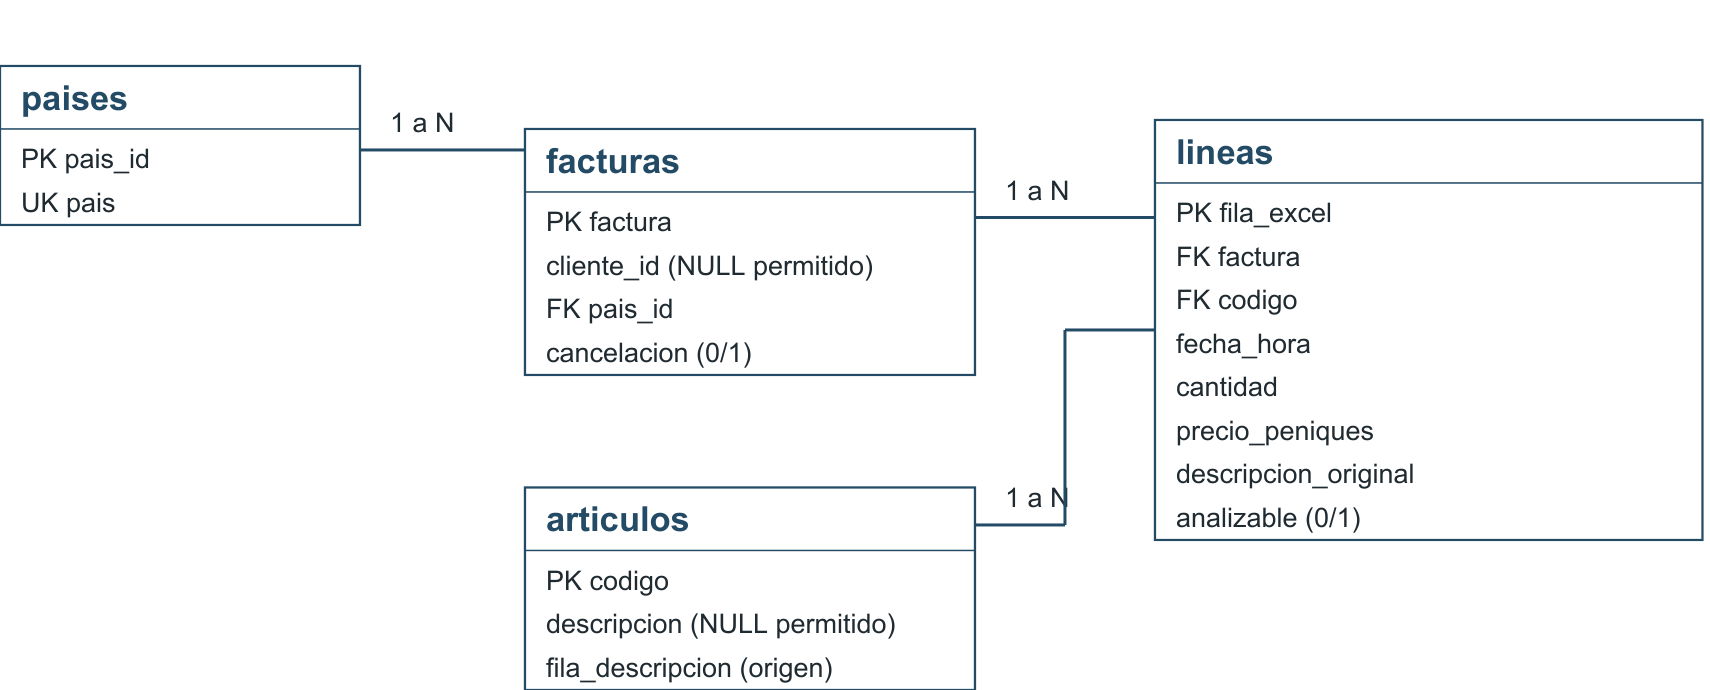

In [12]:
# El SQL queda también como archivo para poder leer el modelo por separado.
esquema <- c(
  "CREATE TABLE paises (
     pais_id INTEGER PRIMARY KEY,
     pais TEXT NOT NULL UNIQUE CHECK(length(trim(pais)) > 0)
   )",
  "CREATE TABLE facturas (
     factura TEXT PRIMARY KEY NOT NULL CHECK(length(factura) > 0),
     cliente_id TEXT,
     pais_id INTEGER NOT NULL REFERENCES paises(pais_id),
     cancelacion INTEGER NOT NULL CHECK(cancelacion IN (0,1)),
     CHECK(cancelacion = CASE WHEN substr(factura,1,1) = 'C' THEN 1 ELSE 0 END)
   )",
  "CREATE TABLE articulos (
     codigo TEXT PRIMARY KEY NOT NULL CHECK(length(codigo) > 0),
     descripcion TEXT,
     fila_descripcion INTEGER CHECK(fila_descripcion >= 2),
     CHECK((descripcion IS NULL AND fila_descripcion IS NULL) OR
           (descripcion IS NOT NULL AND fila_descripcion IS NOT NULL))
   )",
  "CREATE TABLE lineas (
     fila_excel INTEGER PRIMARY KEY CHECK(fila_excel >= 2),
     factura TEXT NOT NULL REFERENCES facturas(factura),
     codigo TEXT NOT NULL REFERENCES articulos(codigo),
     fecha_hora TEXT NOT NULL CHECK(length(fecha_hora) = 19
       AND strftime('%Y-%m-%d %H:%M:%S', fecha_hora) IS NOT NULL),
     cantidad INTEGER NOT NULL CHECK(typeof(cantidad) = 'integer'),
     precio_peniques INTEGER NOT NULL CHECK(precio_peniques >= 0 AND typeof(precio_peniques) = 'integer'),
     descripcion_original TEXT,
     analizable INTEGER NOT NULL CHECK(analizable IN (0,1)),
     CHECK(analizable = CASE WHEN precio_peniques > 0 AND cantidad != 0 THEN 1 ELSE 0 END)
   )"
)
writeLines(paste0(esquema, ";"), file.path(raiz, "sql", "esquema.sql"), useBytes = TRUE)

Activo `foreign_keys` en cada conexión. La carga usa una transacción: se confirma cuando pasan los controles y se revierte si ocurre un error. `on.exit` cierra la conexión al salir de la función. Cada ejecución reemplaza la base generada.

In [13]:
abrir_base <- function(ruta) {
  conexion <- dbConnect(SQLite(), ruta)
  tryCatch({
    dbExecute(conexion, "PRAGMA foreign_keys = ON")
    stopifnot(dbGetQuery(conexion, "PRAGMA foreign_keys")[[1]] == 1)
    conexion
  }, error = function(e) {
    dbDisconnect(conexion)
    stop(e)
  })
}

crear_base <- function(ruta) {
  # Sólo se reemplaza la base generada. Nunca se modifica el Excel original.
  if (file.exists(ruta)) stopifnot(file.remove(ruta))
  conexion <- abrir_base(ruta)
  on.exit(dbDisconnect(conexion))
  dbWithTransaction(conexion, {
    for (sentencia in esquema) dbExecute(conexion, sentencia)
    dbAppendTable(conexion, "paises", paises)
    dbAppendTable(conexion, "facturas", facturas)
    dbAppendTable(conexion, "articulos", articulos)
    dbAppendTable(conexion, "lineas", lineas)
    # La transacción se confirma sólo si la carga pasa estos controles.
    stopifnot(nrow(dbGetQuery(conexion, "PRAGMA foreign_key_check")) == 0,
      dbGetQuery(conexion, "SELECT COUNT(*) AS n FROM lineas")$n == nrow(lineas),
      dbGetQuery(conexion, "PRAGMA integrity_check")[[1]] == "ok")
  })
  invisible(ruta)
}
ruta_base <- file.path(raiz, "salidas", "proyecto.sqlite")
crear_base(ruta_base)
cat("Base creada con cuatro tablas relacionadas. La conexión de carga quedó cerrada.\n")

Base creada con cuatro tablas relacionadas. La conexión de carga quedó cerrada.


## 5. Consultas SQL

Los importes se guardan en peniques y se dividen por 100 al mostrarlos en GBP. Neto es la suma de cantidad firmada por precio. Las cancelaciones aportan importes negativos; la columna de cancelaciones los muestra en valor absoluto.

La primera consulta devuelve una fila por mes. Cuenta facturas distintas y calcula ventas, cancelaciones y neto para líneas con precio positivo.

In [14]:
consultas <- list()
consultas$mensual <- "-- Una fila por mes. GBP, sólo líneas con precio positivo.
-- ventas: cantidad positiva; cancelaciones: magnitud del importe negativo.
-- neto = ventas - cancelaciones. No es ganancia ni ingreso contable auditado.
SELECT substr(l.fecha_hora,1,7) AS mes,
       COUNT(*) AS lineas,
       COUNT(DISTINCT f.factura) AS facturas,
       SUM(CASE WHEN f.cancelacion=0 THEN l.cantidad*l.precio_peniques ELSE 0 END)/100.0 AS ventas_gbp,
       -SUM(CASE WHEN f.cancelacion=1 THEN l.cantidad*l.precio_peniques ELSE 0 END)/100.0 AS cancelaciones_gbp,
       SUM(l.cantidad*l.precio_peniques)/100.0 AS neto_gbp
FROM lineas l JOIN facturas f ON l.factura=f.factura
WHERE l.analizable=1
GROUP BY substr(l.fecha_hora,1,7)
ORDER BY mes"

La consulta por país enlaza líneas, facturas y países. El porcentaje usa el neto de **todos los países** como denominador.

In [15]:
consultas$paises <- "-- Una fila por país del cliente informado en la factura.
-- Participación = neto del país / neto de todos los países analizados, por 100.
SELECT p.pais, COUNT(*) AS lineas, COUNT(DISTINCT f.factura) AS facturas,
       SUM(l.cantidad*l.precio_peniques)/100.0 AS neto_gbp,
       100.0*SUM(l.cantidad*l.precio_peniques)/
         (SELECT SUM(cantidad*precio_peniques) FROM lineas WHERE analizable=1) AS porcentaje_neto
FROM lineas l JOIN facturas f ON l.factura=f.factura
JOIN paises p ON f.pais_id=p.pais_id
WHERE l.analizable=1
GROUP BY p.pais_id, p.pais
ORDER BY neto_gbp DESC, p.pais"

Por artículo, sumo cantidades dentro del mismo código. Las unidades netas son las positivas menos las canceladas. Algunos códigos del archivo representan cargos.

In [16]:
consultas$articulos <- "-- Una fila por código de artículo o concepto. Cantidades del mismo código.
-- Unidades netas = positivas + negativas. Se ordenan todos los códigos.
-- Algunos códigos de la fuente representan cargos como envío, no objetos físicos.
SELECT a.codigo, a.descripcion, COUNT(*) AS lineas,
       SUM(CASE WHEN l.cantidad>0 THEN l.cantidad ELSE 0 END) AS unidades_positivas,
       -SUM(CASE WHEN l.cantidad<0 THEN l.cantidad ELSE 0 END) AS unidades_canceladas,
       SUM(l.cantidad) AS unidades_netas,
       SUM(l.cantidad*l.precio_peniques)/100.0 AS neto_gbp
FROM lineas l JOIN articulos a ON l.codigo=a.codigo
WHERE l.analizable=1
GROUP BY a.codigo, a.descripcion
ORDER BY unidades_netas DESC, a.codigo"

Las demás consultas controlan los JOIN, los faltantes y los totales, recuperan el caso conocido y miden la sensibilidad a las repeticiones. El control de JOIN utiliza las cuatro tablas.

In [17]:
consultas$control_joins <- "-- Un control global que utiliza las cuatro tablas.
-- Filas y dinero deben coincidir con la tabla lineas sin JOIN.
SELECT COUNT(*) AS filas, COUNT(DISTINCT l.fila_excel) AS filas_distintas,
       SUM(l.cantidad*l.precio_peniques) AS importe_peniques
FROM lineas l JOIN facturas f ON l.factura=f.factura
JOIN paises p ON f.pais_id=p.pais_id
JOIN articulos a ON l.codigo=a.codigo"

In [18]:
consultas$calidad <- "-- Una fila de control: incluye todas las líneas, también las no analizadas.
-- Los faltantes de cliente se cuentan por renglón, no por cliente.
SELECT COUNT(*) AS filas,
       SUM(CASE WHEN f.cliente_id IS NULL THEN 1 ELSE 0 END) AS sin_cliente,
       SUM(CASE WHEN l.precio_peniques=0 THEN 1 ELSE 0 END) AS precio_cero,
       SUM(CASE WHEN l.analizable=1 THEN 1 ELSE 0 END) AS analizadas,
       COUNT(DISTINCT l.factura) AS facturas,
       COUNT(DISTINCT l.codigo) AS articulos
FROM lineas l JOIN facturas f ON l.factura=f.factura"

In [19]:
consultas$caso_conocido <- "-- Las dos filas de un caso concreto del Excel. Importe en peniques.
SELECT fila_excel, factura, codigo, fecha_hora, cantidad, precio_peniques,
       cantidad*precio_peniques AS importe_peniques
FROM lineas WHERE fila_excel IN (61621,61626) ORDER BY fila_excel"

In [20]:
consultas$repeticiones <- "-- Identidad en los ocho campos recibidos: país y cliente dependen de factura.
-- Filas extra significa copias posteriores a la primera, sin afirmar que sean errores.
-- Sensibilidad: cuánto dinero se restaría si se decidiera conservar sólo la primera.
SELECT COALESCE(SUM(n-1),0) AS filas_extra,
       COALESCE(SUM(CASE WHEN analizable=1 THEN (n-1)*importe ELSE 0 END),0)/100.0 AS diferencia_gbp
FROM (
 SELECT COUNT(*) AS n, analizable, cantidad*precio_peniques AS importe
 FROM lineas
 GROUP BY factura,codigo,descripcion_original,cantidad,fecha_hora,precio_peniques,analizable
 HAVING COUNT(*)>1
)"

In [21]:
consultas$totales <- "-- Totales de control. Importe firmado en peniques, sin sumar unidades de artículos distintos.
SELECT COUNT(*) AS filas, SUM(cantidad*precio_peniques) AS importe_peniques
FROM lineas"

Ejecuto las consultas con `dbGetQuery` y exporto los resultados. En pantalla muestro las primeras filas de cada tabla.

In [22]:
texto_sql <- character()
for (nombre in names(consultas)) {
  texto_sql <- c(texto_sql, paste0("-- CONSULTA: ", nombre, "\n", consultas[[nombre]], ";\n"))
}
writeLines(texto_sql, file.path(raiz, "sql", "consultas.sql"), useBytes = TRUE)

consultar_base <- function(ruta) {
  conexion <- abrir_base(ruta)
  on.exit(dbDisconnect(conexion))
  tablas <- list()
  for (nombre in names(consultas)) {
    tablas[[nombre]] <- dbGetQuery(conexion, consultas[[nombre]])
  }
  tablas
}
resultados <- consultar_base(ruta_base)
for (nombre in names(resultados)) {
  cat("\nConsulta:", nombre, "\n")
  print(head(resultados[[nombre]], 10))
  guardar_csv(resultados[[nombre]], paste0(nombre, ".csv"))
}


Consulta: mensual 
      mes lineas facturas ventas_gbp cancelaciones_gbp neto_gbp
1 2011-01  35007     1346   691364.6         131364.30 560000.3
2 2011-02  27580     1319   523631.9          25569.24 498062.7
3 2011-03  36502     1772   717639.4          34372.28 683267.1

Consulta: paises 
             pais lineas facturas   neto_gbp porcentaje_neto
1  United Kingdom  90238     3973 1402263.60      80.5283093
2     Netherlands    609       20   71959.76       4.1324597
3            EIRE   1194       52   50113.89       2.8779089
4       Australia    328       19   40700.47       2.3373209
5          France   1651       94   40458.88       2.3234470
6         Germany   1780      113   39590.69       2.2735892
7           Spain    689       25   14598.89       0.8383758
8     Switzerland    321       12    8744.13       0.5021524
9          Sweden     83        8    8496.40       0.4879259
10       Portugal    293       12    7872.86       0.4521176

Consulta: articulos 
   codigo   

## 6. Verificaciones

Compruebo lo siguiente con `stopifnot`:

- **Caso conocido:** 74.215 × 104 = 7.718.360 peniques; la cancelación tiene el importe opuesto.
- **Casos límite:** textos vacíos, cliente ausente, fecha imposible, precios inválidos y ceros, separados de los datos.
- **Integridad:** claves únicas, `foreign_key_check` sin filas y JOIN sin multiplicar líneas ni dinero.
- **SQL contra R y conservación:** neto mensual igual y conteos conciliados con la bitácora.
- **Rollback:** una línea con factura inexistente debe revertir también la inserción válida anterior.
- **Repetición:** otra base creada desde cero debe devolver las ocho consultas iguales.

La tabla final registra el resultado de las pruebas. Si falla una condición, la función se detiene y cierra la conexión.

In [23]:
# Pruebas sobre la base creada y algunos ejemplos separados del archivo.
verificar <- function() {
  con <- abrir_base(ruta_base)
  on.exit(dbDisconnect(con))

  # 74215 * 104 = 7718360 peniques; la cancelación tiene el importe opuesto.
  caso <- resultados$caso_conocido
  stopifnot(nrow(caso) == 2, all(caso$precio_peniques == 104),
            all(caso$importe_peniques == c(7718360, -7718360)),
            sum(caso$importe_peniques) == 0)

  texto <- trimws(c(" nombre ", "", "?", NA_character_))
  texto[texto %in% c("", "?")] <- NA_character_
  stopifnot(identical(texto, c("nombre", NA_character_, NA_character_, NA_character_)))
  precios <- c(0, 1.04, 1.005)
  stopifnot(identical(abs(precios * 100 - round(precios * 100)) < 1e-6,
                      c(TRUE, TRUE, FALSE)))
  fechas <- as.Date(c("2011-02-28", "2011-02-30"), format = "%Y-%m-%d")
  stopifnot(!is.na(fechas[1]), is.na(fechas[2]))
  clientes <- c(12346, NA_real_)
  stopifnot(identical(ifelse(is.na(clientes), NA_character_, sprintf("%.0f", clientes)),
                      c("12346", NA_character_)))
  precio_invalido <- tryCatch({
    stopifnot(all(c(1.04, -1) >= 0))
    FALSE
  }, error = function(e) TRUE)
  stopifnot(precio_invalido,
            identical(as.integer(c(100, 0, 100) > 0 & c(2, 2, 0) != 0), c(1L, 0L, 0L)))

  # Claves y relaciones. El JOIN debe conservar filas e importe.
  stopifnot(!anyDuplicated(paises$pais_id), !anyDuplicated(facturas$factura),
            !anyDuplicated(articulos$codigo), !anyDuplicated(lineas$fila_excel),
            nrow(dbGetQuery(con, "PRAGMA foreign_key_check")) == 0,
            dbGetQuery(con, "PRAGMA integrity_check")[[1]] == "ok",
            resultados$control_joins$filas == resultados$totales$filas,
            resultados$control_joins$filas_distintas == nrow(lineas),
            resultados$control_joins$importe_peniques == resultados$totales$importe_peniques)

  analisis <- ventas[ventas$analizable == 1, ]
  analisis$mes <- substr(analisis$fecha_hora, 1, 7)
  analisis$importe <- analisis$cantidad * analisis$precio_peniques
  mensual_r <- aggregate(importe ~ mes, analisis, sum)
  stopifnot(identical(mensual_r$mes, resultados$mensual$mes),
            all(mensual_r$importe == round(resultados$mensual$neto_gbp * 100)))

  stopifnot(nrow(ventas_original) == sum(!en_periodo) + nrow(muestra),
            nrow(muestra) == nrow(lineas),
            nrow(lineas) == sum(lineas$analizable == 1) + sum(lineas$analizable == 0),
            resultados$repeticiones$filas_extra == sum(repetidas),
            bitacora$filas_despues[bitacora$regla == "seleccion_periodo"] == nrow(lineas),
            bitacora$afectados[bitacora$regla == "precio_cero_fuera_del_analisis"] == sum(lineas$analizable == 0),
            unname(tools::md5sum(archivo)) == md5_original)

  # La segunda inserción debe fallar y revertir también la primera.
  paises_antes <- dbGetQuery(con, "SELECT COUNT(*) AS n FROM paises")$n
  error_fk <- tryCatch({
    dbWithTransaction(con, {
      dbExecute(con, "INSERT INTO paises VALUES (999999, 'PAIS DE PRUEBA')")
      dbExecute(con, "INSERT INTO lineas
        SELECT 9999999, 'FACTURA_INEXISTENTE', codigo, '2011-01-01 00:00:00', 1, 100, NULL, 1
        FROM articulos LIMIT 1")
    })
    "Sin error"
  }, error = function(e) conditionMessage(e))
  stopifnot(grepl("FOREIGN KEY", error_fk, fixed = TRUE),
            dbGetQuery(con, "SELECT COUNT(*) AS n FROM paises")$n == paises_antes,
            dbGetQuery(con, "SELECT COUNT(*) AS n FROM paises WHERE pais_id=999999")$n == 0,
            dbGetQuery(con, "SELECT COUNT(*) AS n FROM lineas WHERE fila_excel=9999999")$n == 0)

  segunda_base <- tempfile(fileext = ".sqlite")
  on.exit(unlink(segunda_base), add = TRUE)
  crear_base(segunda_base)
  stopifnot(isTRUE(all.equal(resultados, consultar_base(segunda_base), tolerance = 0)))

  data.frame(
    prueba = c("Caso conocido", "Casos límite", "Integridad y JOIN", "SQL contra R",
               "Conservación", "Rollback", "Segunda reconstrucción"),
    resultado = "OK",
    evidencia = c("Compra y cancelación: +77183,60 y -77183,60 GBP",
      "Textos, cliente ausente, fecha imposible, precios inválidos y ceros",
      "Claves únicas, sin huérfanos y sin multiplicar filas ni dinero",
      "El neto mensual calculado en R coincide con SQL",
      "Filas conciliadas con la bitácora y MD5 del original sin cambios",
      paste("Ninguna inserción de prueba quedó guardada tras", error_fk),
      "Las ocho consultas coinciden en otra base creada desde cero")
  )
}
pruebas <- verificar()
print(pruebas)
guardar_csv(pruebas, "verificaciones.csv")

                  prueba resultado
1          Caso conocido        OK
2           Casos límite        OK
3      Integridad y JOIN        OK
4           SQL contra R        OK
5           Conservación        OK
6               Rollback        OK
7 Segunda reconstrucción        OK
                                                                      evidencia
1                               Compra y cancelación: +77183,60 y -77183,60 GBP
2           Textos, cliente ausente, fecha imposible, precios inválidos y ceros
3                Claves únicas, sin huérfanos y sin multiplicar filas ni dinero
4                               El neto mensual calculado en R coincide con SQL
5              Filas conciliadas con la bitácora y MD5 del original sin cambios
6 Ninguna inserción de prueba quedó guardada tras FOREIGN KEY constraint failed
7                   Las ocho consultas coinciden en otra base creada desde cero


## 7. Gráficos y resultados

Los tres gráficos usan tablas obtenidas en SQLite. Las barras permiten comparar meses, países y códigos de artículo.

### Ventas por mes

**Marzo tiene el mayor neto: 683.267,08 GBP**, frente a 498.062,65 GBP de febrero. Enero concentra más importe cancelado: 131.364,30 GBP. El caso de la compra grande aporta 77.183,60 GBP tanto a ventas como a cancelaciones.

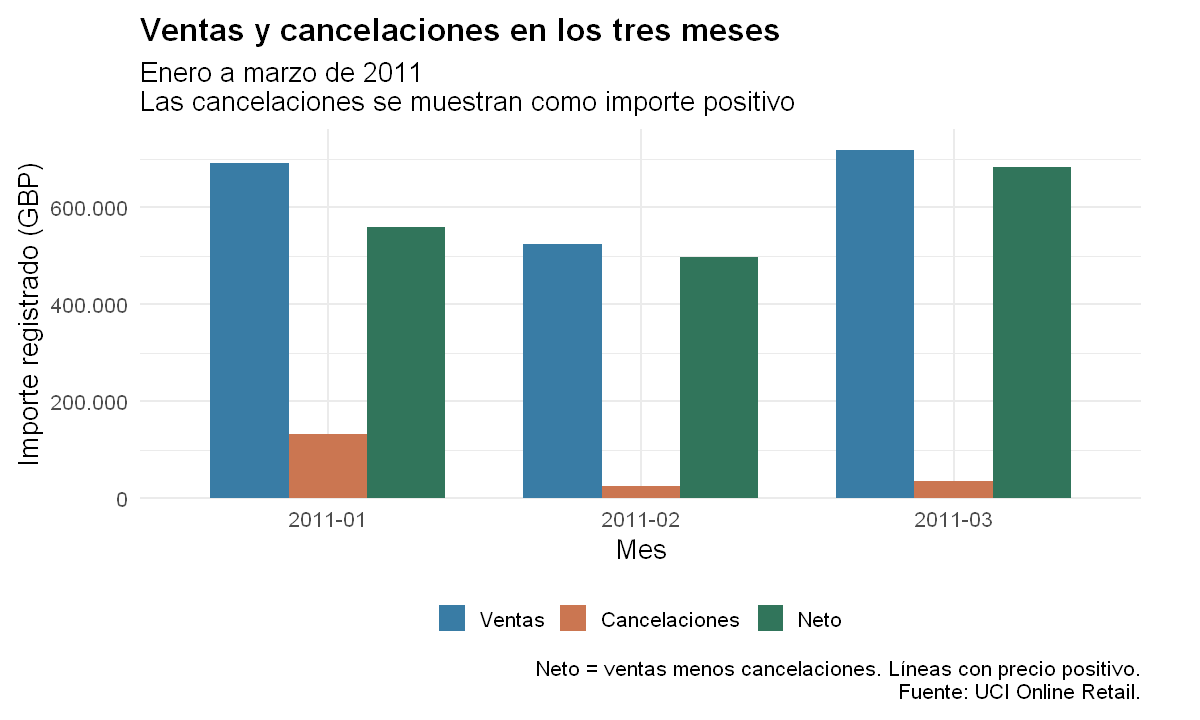

In [24]:
# Los gráficos usan las tablas consultadas en SQLite.
theme_set(theme_minimal(base_size = 16) + theme(plot.margin = margin(10, 35, 10, 10)))
numero <- function(x, decimales = 0) {
  formatC(x, format = "f", digits = decimales, big.mark = ".", decimal.mark = ",")
}

mensual <- resultados$mensual
mensual_grafico <- rbind(
  data.frame(mes = mensual$mes, tipo = "Ventas", importe = mensual$ventas_gbp),
  data.frame(mes = mensual$mes, tipo = "Cancelaciones", importe = mensual$cancelaciones_gbp),
  data.frame(mes = mensual$mes, tipo = "Neto", importe = mensual$neto_gbp)
)
mensual_grafico$tipo <- factor(mensual_grafico$tipo, levels = c("Ventas", "Cancelaciones", "Neto"))
g1 <- ggplot(mensual_grafico, aes(mes, importe, fill = tipo)) +
  geom_col(position = "dodge", width = 0.75) +
  scale_fill_manual(values = c("Ventas" = "#397CA5", "Cancelaciones" = "#CB7651", "Neto" = "#31755B")) +
  scale_y_continuous(labels = numero, expand = expansion(mult = c(0, 0.06))) +
  labs(title = "Ventas y cancelaciones en los tres meses",
    subtitle = "Enero a marzo de 2011\nLas cancelaciones se muestran como importe positivo",
    x = "Mes", y = "Importe registrado (GBP)", fill = NULL,
    caption = "Neto = ventas menos cancelaciones. Líneas con precio positivo.\nFuente: UCI Online Retail.") +
  theme(legend.position = "bottom", plot.title = element_text(face = "bold"))
print(g1)
ggsave(file.path(resultados_dir, "grafico_1_meses.png"), g1, width = 10, height = 5.6, dpi = 160)

### Países

**Reino Unido concentra el 80,5 % del neto**, con 1.402.263,60 GBP. Después aparece Países Bajos, con aproximadamente 4,1 %. El gráfico muestra los ocho mayores, pero los porcentajes usan los 31 países.

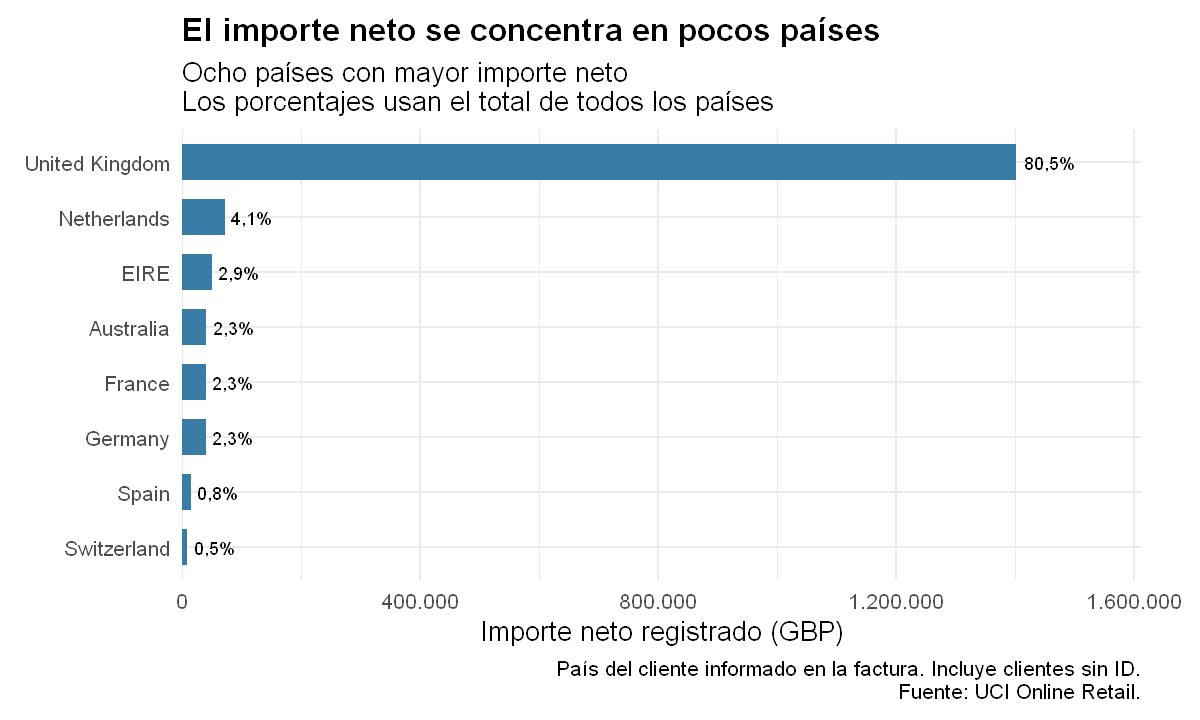

In [25]:
principales_paises <- head(resultados$paises, 8)
g2 <- ggplot(principales_paises, aes(reorder(pais, neto_gbp), neto_gbp)) +
  geom_col(fill = "#397CA5", width = 0.65) +
  geom_text(aes(label = paste0(numero(porcentaje_neto, 1), "%")), hjust = -0.15, size = 3.8) +
  coord_flip() +
  scale_y_continuous(labels = numero, expand = expansion(mult = c(0, 0.15))) +
  labs(title = "El importe neto se concentra en pocos países",
    subtitle = "Ocho países con mayor importe neto\nLos porcentajes usan el total de todos los países",
    x = NULL, y = "Importe neto registrado (GBP)",
    caption = "País del cliente informado en la factura. Incluye clientes sin ID.\nFuente: UCI Online Retail.") +
  theme(plot.title = element_text(face = "bold"))
print(g2)
ggsave(file.path(resultados_dir, "grafico_2_paises.png"), g2, width = 10, height = 5.6, dpi = 160)

### Artículos

El código **85099B**, JUMBO BAG RED RETROSPOT, tiene **10.996 unidades netas**. Le siguen 21212 con 9.479 y 85123A con 9.377. Los nombres se mantienen como aparecen en la fuente.

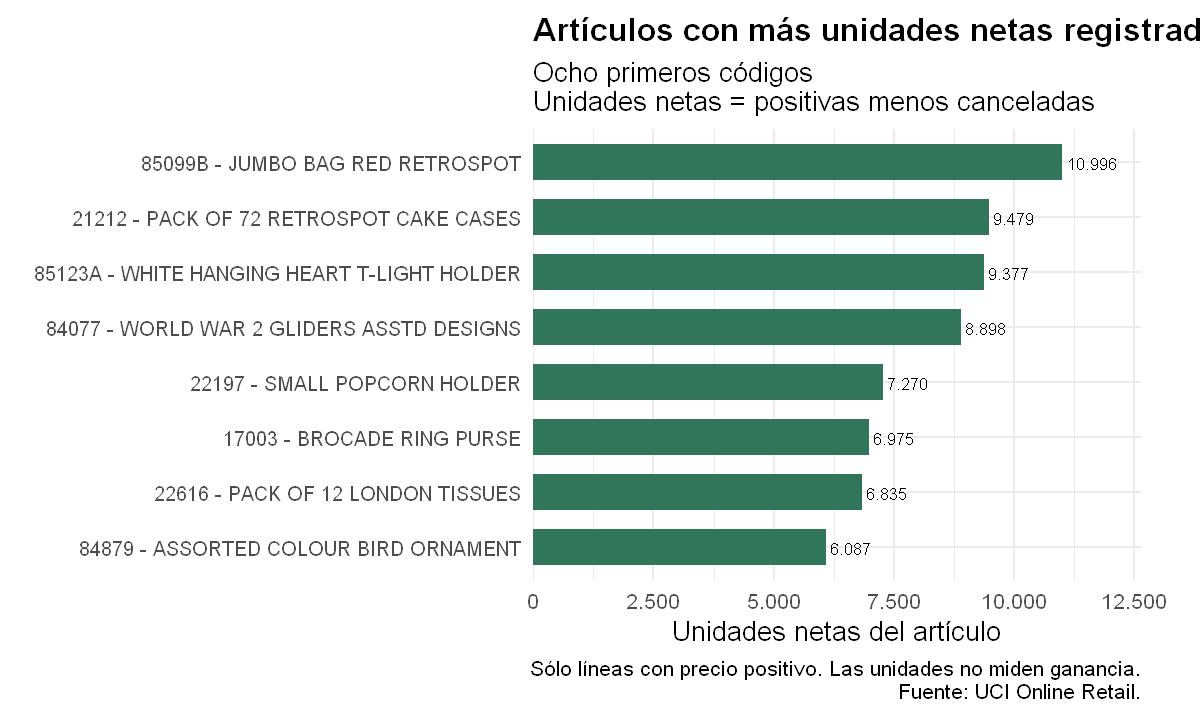

In [26]:
principales_articulos <- head(resultados$articulos, 8)
principales_articulos$etiqueta <- paste(principales_articulos$codigo, principales_articulos$descripcion, sep = " - ")
g3 <- ggplot(principales_articulos, aes(reorder(etiqueta, unidades_netas), unidades_netas)) +
  geom_col(fill = "#31755B", width = 0.65) +
  geom_text(aes(label = numero(unidades_netas)), hjust = -0.1, size = 3.6) +
  coord_flip() +
  scale_y_continuous(labels = numero, expand = expansion(mult = c(0, 0.15))) +
  labs(title = "Artículos con más unidades netas registradas",
    subtitle = "Ocho primeros códigos\nUnidades netas = positivas menos canceladas",
    x = NULL, y = "Unidades netas del artículo",
    caption = "Sólo líneas con precio positivo. Las unidades no miden ganancia.\nFuente: UCI Online Retail.") +
  theme(plot.title = element_text(face = "bold"), axis.text.y = element_text(size = 12))
print(g3)
ggsave(file.path(resultados_dir, "grafico_3_articulos.png"), g3, width = 12, height = 5.6, dpi = 160)

### Alcance de los resultados

El neto del trimestre es **1.741.329,99 GBP**. Quitar las copias posteriores de filas idénticas lo bajaría 3.841,04 GBP, alrededor del 0,22 %.

Estos datos describen una tienda con clientes mayoristas en tres meses de 2011. Faltan costos para calcular ganancias y motivos para explicar cancelaciones. Algunas pueden corresponder a compras de otro período. Las cantidades de packs son unidades comerciales y los países representan la clientela registrada. El análisis no se extiende a las ventas de OnCloud.

Guardo un resumen y las versiones de R y los paquetes para poder repetir el proceso.

In [27]:
mejor_mes <- mensual$mes[which.max(mensual$neto_gbp)]
peor_mes <- mensual$mes[which.min(mensual$neto_gbp)]
participacion_uk <- resultados$paises$porcentaje_neto[resultados$paises$pais == "United Kingdom"]
hallazgos <- c(
  paste0("Selección: ", numero(nrow(lineas)), " renglones; ",
         numero(sum(lineas$analizable == 1)), " con precio positivo."),
  paste0("Mayor neto mensual: ", mejor_mes, "; menor: ", peor_mes, "."),
  paste0("Reino Unido: ", numero(participacion_uk, 1), "% del neto del trimestre."),
  paste0("Primer artículo por unidades netas: ", principales_articulos$codigo[1],
         ", con ", numero(principales_articulos$unidades_netas[1]), "."),
  paste0("Quitar las copias posteriores de filas idénticas bajaría el neto en ",
         numero(resultados$repeticiones$diferencia_gbp, 2), " GBP."),
  "Los resultados describen los registros de esta tienda en enero a marzo de 2011."
)
cat(paste(hallazgos, collapse = "\n\n"), "\n")
writeLines(hallazgos, file.path(raiz, "salidas", "hallazgos.txt"), useBytes = TRUE)
capture.output(sessionInfo(), file = file.path(raiz, "salidas", "sessionInfo.txt"))
versiones <- data.frame(paquete = paquetes,
  version = sapply(paquetes, function(x) as.character(packageVersion(x))))
guardar_csv(versiones, "versiones_paquetes.csv")
stopifnot(unname(tools::md5sum(archivo)) == md5_original)
cat("Salidas guardadas en:", resultados_dir, "\n")

Selección: 99.602 renglones; 99.089 con precio positivo.

Mayor neto mensual: 2011-03; menor: 2011-02.

Reino Unido: 80,5% del neto del trimestre.

Primer artículo por unidades netas: 85099B, con 10.996.

Quitar las copias posteriores de filas idénticas bajaría el neto en 3.841,04 GBP.

Los resultados describen los registros de esta tienda en enero a marzo de 2011. 


Salidas guardadas en: ./salidas/resultados 


## Entrega

Se incluyen el notebook con salidas, originales, diccionario, procedencia, scripts R, SQL, base SQLite, bitácora y resultados. La presentación tiene trece diapositivas y termina con los tres gráficos. La propuesta de fuente queda para presentar a la cátedra según los hitos de EVA.

Para repetir el análisis, reiniciar el kernel y ejecutar todas las celdas. El Excel incluido permite trabajar aunque falle la descarga.